# Linear Regression

## Prediksi Tekanan Darah Sistolik (ap_hi)

## 1. Import Library

In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## 2. Memuat Dataset

In [2]:
# Memuat dataset yang sudah dibersihkan
df = pd.read_csv("../data/processed/cardio_cleaned.csv")

# Memeriksa ukuran dan isi dataset
print("Ukuran dataset:", df.shape)
display(df.head())

Ukuran dataset: (68652, 13)


,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,18393,2,168,62.0,110,80,1,1,0,0,1,0
1,1,20228,1,156,85.0,140,90,3,1,0,0,1,1
2,2,18857,1,165,64.0,130,70,3,1,0,0,0,1
3,3,17623,2,169,82.0,150,100,1,1,0,0,1,1
4,4,17474,1,156,56.0,100,60,1,1,0,0,0,0


## 3. Menentukan Fitur dan Target

In [3]:
# Memisahkan fitur (X) dan target (y)
X = df.drop(columns=["id", "ap_hi", "cardio"])
y = df["ap_hi"]

# Memeriksa ukuran fitur dan target
print("Ukuran X:", X.shape)
print("Ukuran y:", y.shape)

print("\nDaftar fitur:")
print(X.columns.tolist())

Ukuran X: (68652, 10)
Ukuran y: (68652,)

Daftar fitur:
['age', 'gender', 'height', 'weight', 'ap_lo', 'cholesterol', 'gluc', 'smoke', 'alco', 'active']


## 4. Train-Test Split

In [4]:
# Membagi dataset menjadi data training dan testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# Memeriksa ukuran data
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (54921, 10)
X_test: (13731, 10)
y_train: (54921,)
y_test: (13731,)


## 5. Preprocessing
### 5.1 Menentukan Kelompok Fitur

In [5]:
# Fitur kategori nominal
categorical_features = ["gender"]

# Fitur numerik
numeric_features = [
    "age",
    "height",
    "weight",
    "ap_lo",
    "cholesterol",
    "gluc",
    "smoke",
    "alco",
    "active"
]

print("Fitur kategori:", categorical_features)
print("Fitur numerik:", numeric_features)

Fitur kategori: ['gender']
Fitur numerik: ['age', 'height', 'weight', 'ap_lo', 'cholesterol', 'gluc', 'smoke', 'alco', 'active']


In [6]:
# Import preprocessing tools
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Membuat preprocessing transformer
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

In [7]:
# Preprocessing data training
X_train_processed = preprocessor.fit_transform(X_train)

# Preprocessing data testing
X_test_processed = preprocessor.transform(X_test)

# Memeriksa ukuran hasil preprocessing
print("X_train setelah preprocessing:", X_train_processed.shape)
print("X_test setelah preprocessing:", X_test_processed.shape)

X_train setelah preprocessing: (54921, 11)
X_test setelah preprocessing: (13731, 11)


## 6. Model Training
### 6.1 Melatih Model Linear Regression

In [8]:
# Membuat model Linear Regression
linear_model = LinearRegression()

# Melatih model menggunakan data training
linear_model.fit(X_train_processed, y_train)

print("Model Linear Regression berhasil dilatih!")

Model Linear Regression berhasil dilatih!


### 6.2 Melakukan Prediksi

In [9]:
# Melakukan prediksi menggunakan data testing
y_pred = linear_model.predict(X_test_processed)

# Membandingkan nilai aktual dengan hasil prediksi
comparison = pd.DataFrame({
    "Aktual": y_test.values,
    "Prediksi": y_pred
})

# Menghitung selisih antara nilai aktual dan prediksi
comparison["Selisih"] = comparison["Aktual"] - comparison["Prediksi"]

# Menampilkan 10 hasil prediksi pertama
display(comparison.head(10))

print("Jumlah hasil prediksi:", len(y_pred))

,Aktual,Prediksi,Selisih
0,130,128.881938,1.118062
1,120,128.435362,-8.435362
2,120,125.936951,-5.936951
3,150,126.718192,23.281808
4,130,124.340745,5.659255
5,140,126.441474,13.558526
6,130,154.233139,-24.233139
7,120,129.896918,-9.896918
8,120,125.077887,-5.077887
9,170,148.296235,21.703765


Jumlah hasil prediksi: 13731


### 6.3 Evaluasi Model

In [10]:
# Menghitung metrik evaluasi
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

# Menampilkan hasil evaluasi
print("Hasil Evaluasi Linear Regression")
print("--------------------------------")
print("MAE :", mae)
print("MSE :", mse)
print("RMSE:", rmse)
print("R²  :", r2)

Hasil Evaluasi Linear Regression
--------------------------------
MAE : 8.054478264461162
MSE : 129.74269554176644
RMSE: 11.390465115251722
R²  : 0.5442539114303923


### 6.4 Visualisasi Actual vs Predicted

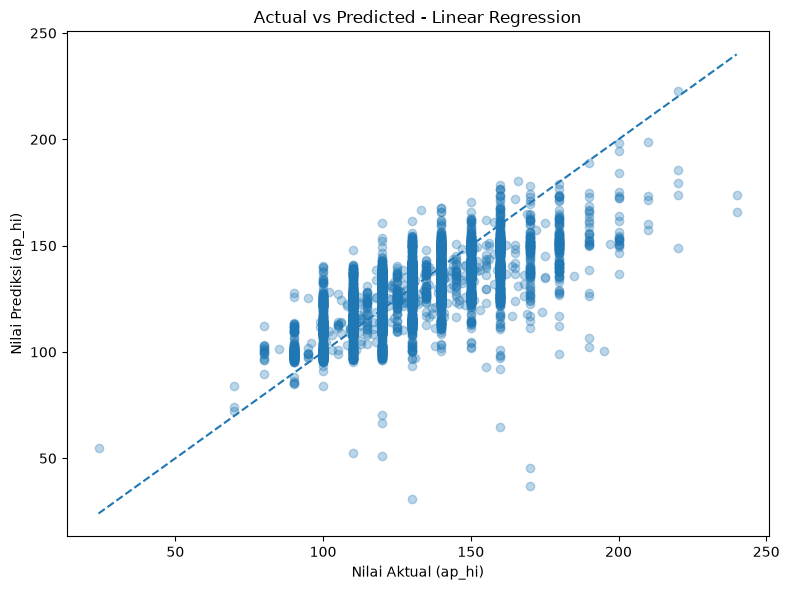

In [11]:
import matplotlib.pyplot as plt

# Membuat visualisasi nilai aktual dan prediksi
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.3)

# Garis prediksi ideal
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.xlabel("Nilai Aktual (ap_hi)")
plt.ylabel("Nilai Prediksi (ap_hi)")
plt.title("Actual vs Predicted - Linear Regression")

plt.tight_layout()
plt.show()

## 7. Kesimpulan

Model Linear Regression berhasil dibangun untuk memprediksi tekanan darah sistolik (ap_hi) menggunakan 10 fitur dari dataset Cardiovascular Disease.

Evaluasi pada data testing menghasilkan:
- MAE: 8.05
- MSE: 129.74
- RMSE: 11.39
- R²: 0.5443

Hasil visualisasi Actual vs Predicted menunjukkan bahwa sebagian besar titik cenderung berkumpul di sekitar garis diagonal, meskipun masih terdapat beberapa titik yang menyebar.

Secara keseluruhan, model mampu menjelaskan sekitar 54.43% variasi nilai tekanan darah sistolik. Hal ini menunjukkan bahwa model telah menangkap sebagian pola data, tetapi kemampuan prediksinya masih moderat dan masih dapat ditingkatkan.